In [27]:
import pandas as pd
import numpy as np

In [28]:
csv='../01.data/raw/ATOM_USD_ML_features.csv'
df = pd.read_csv(csv, parse_dates=["date"])
df.head(3)

,date,symbol,last_price,open,high,low,volume,last_return,return_3d,returnvola_3d,...,rsi_14,bb_upper_20,bb_lower_20,bb_width_20,high_low_range_pct,day_of_week,month,Surge,target_next_close,target_next_return
0,2020-01-26,ATOM/USD,4.480,4.379,4.505,4.363,355850.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.032427,6,1,0,4.515,0.007812
1,2020-01-27,ATOM/USD,4.515,4.474,4.672,4.401,1080000.0,0.007812,NaN,NaN,...,NaN,NaN,NaN,NaN,0.060572,0,1,1,4.601,0.019048
2,2020-01-28,ATOM/USD,4.601,4.516,4.609,4.473,577350.0,0.019048,NaN,NaN,...,NaN,NaN,NaN,NaN,0.030115,1,1,1,4.401,-0.043469


In [29]:
print(df["date"].min().date(), "->", df["date"].max().date())

2020-01-26 -> 2026-09-26


In [30]:
df.dtypes

date                  datetime64[us]
symbol                           str
last_price                   float64
open                         float64
high                         float64
low                          float64
volume                       float64
last_return                  float64
return_3d                    float64
returnvola_3d                float64
volume_3d                    float64
volumevola_3d                float64
return_7d                    float64
returnvola_7d                float64
volume_7d                    float64
volumevola_7d                float64
return_14d                   float64
returnvola_14d               float64
volume_14d                   float64
volumevola_14d               float64
return_21d                   float64
returnvola_21d               float64
volume_21d                   float64
volumevola_21d               float64
return_30d                   float64
returnvola_30d               float64
volume_30d                   float64
v

In [31]:
print(df.nunique().sort_values().head(5))

symbol           1
Surge            2
day_of_week      7
month           12
volume         912
dtype: int64


In [32]:
df = df.drop(columns=["symbol"]).copy()

In [33]:
df_features = df.columns
df_features

Index(['date', 'last_price', 'open', 'high', 'low', 'volume', 'last_return',
       'return_3d', 'returnvola_3d', 'volume_3d', 'volumevola_3d', 'return_7d',
       'returnvola_7d', 'volume_7d', 'volumevola_7d', 'return_14d',
       'returnvola_14d', 'volume_14d', 'volumevola_14d', 'return_21d',
       'returnvola_21d', 'volume_21d', 'volumevola_21d', 'return_30d',
       'returnvola_30d', 'volume_30d', 'volumevola_30d', 'return_60d',
       'returnvola_60d', 'volume_60d', 'volumevola_60d', 'return_90d',
       'returnvola_90d', 'volume_90d', 'volumevola_90d', 'sma_7', 'sma_14',
       'sma_30', 'sma_50', 'sma_90', 'sma_200', 'ema_12', 'ema_26', 'macd',
       'macd_signal', 'rsi_14', 'bb_upper_20', 'bb_lower_20', 'bb_width_20',
       'high_low_range_pct', 'day_of_week', 'month', 'Surge',
       'target_next_close', 'target_next_return'],
      dtype='str')

In [34]:
df.head(1)

,date,last_price,open,high,low,volume,last_return,return_3d,returnvola_3d,volume_3d,...,rsi_14,bb_upper_20,bb_lower_20,bb_width_20,high_low_range_pct,day_of_week,month,Surge,target_next_close,target_next_return
0,2020-01-26,4.48,4.379,4.505,4.363,355850.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.032427,6,1,0,4.515,0.007812


In [35]:
df['date'] = pd.to_datetime(df['date'])

In [36]:
print(df['date'].dtypes)

datetime64[us]


In [37]:
# Convert the date column to a real datetime value for chronological sorting
df['date'] = pd.to_datetime(df['date'])

In [38]:
df.head(1)

,date,last_price,open,high,low,volume,last_return,return_3d,returnvola_3d,volume_3d,...,rsi_14,bb_upper_20,bb_lower_20,bb_width_20,high_low_range_pct,day_of_week,month,Surge,target_next_close,target_next_return
0,2020-01-26,4.48,4.379,4.505,4.363,355850.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.032427,6,1,0,4.515,0.007812


In [39]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2436 entries, 0 to 2435
Data columns (total 55 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   date                2436 non-null   datetime64[us]
 1   last_price          2436 non-null   float64       
 2   open                2436 non-null   float64       
 3   high                2436 non-null   float64       
 4   low                 2436 non-null   float64       
 5   volume              2436 non-null   float64       
 6   last_return         2435 non-null   float64       
 7   return_3d           2433 non-null   float64       
 8   returnvola_3d       2433 non-null   float64       
 9   volume_3d           2434 non-null   float64       
 10  volumevola_3d       2434 non-null   float64       
 11  return_7d           2429 non-null   float64       
 12  returnvola_7d       2429 non-null   float64       
 13  volume_7d           2430 non-null   float64       
 14  vol

In [40]:
#check duplicate rows
df.duplicated().sum()

np.int64(0)

In [41]:
df.head()

,date,last_price,open,high,low,volume,last_return,return_3d,returnvola_3d,volume_3d,...,rsi_14,bb_upper_20,bb_lower_20,bb_width_20,high_low_range_pct,day_of_week,month,Surge,target_next_close,target_next_return
0,2020-01-26,4.480,4.379,4.505,4.363,355850.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.032427,6,1,0,4.515,0.007812
1,2020-01-27,4.515,4.474,4.672,4.401,1080000.0,0.007812,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.060572,0,1,1,4.601,0.019048
2,2020-01-28,4.601,4.516,4.609,4.473,577350.0,0.019048,NaN,NaN,2013200.0,...,NaN,NaN,NaN,NaN,0.030115,1,1,1,4.401,-0.043469
3,2020-01-29,4.401,4.577,4.597,4.355,1070000.0,-0.043469,-0.017634,0.033327,2727350.0,...,NaN,NaN,NaN,NaN,0.052873,2,1,0,4.410,0.002045
4,2020-01-30,4.410,4.399,4.480,4.307,903250.0,0.002045,-0.023256,0.032324,2550600.0,...,NaN,NaN,NaN,NaN,0.039327,3,1,0,4.397,-0.002948


In [42]:
#checking for date sorted or not
df['date'].is_monotonic_increasing

True

In [43]:
df["date"].duplicated().sum()

np.int64(0)

In [44]:
print("gap between days:", df["date"].diff().dt.days.value_counts().to_dict())

gap between days: {1.0: 2435}


In [45]:
df = df.set_index("date").sort_index()

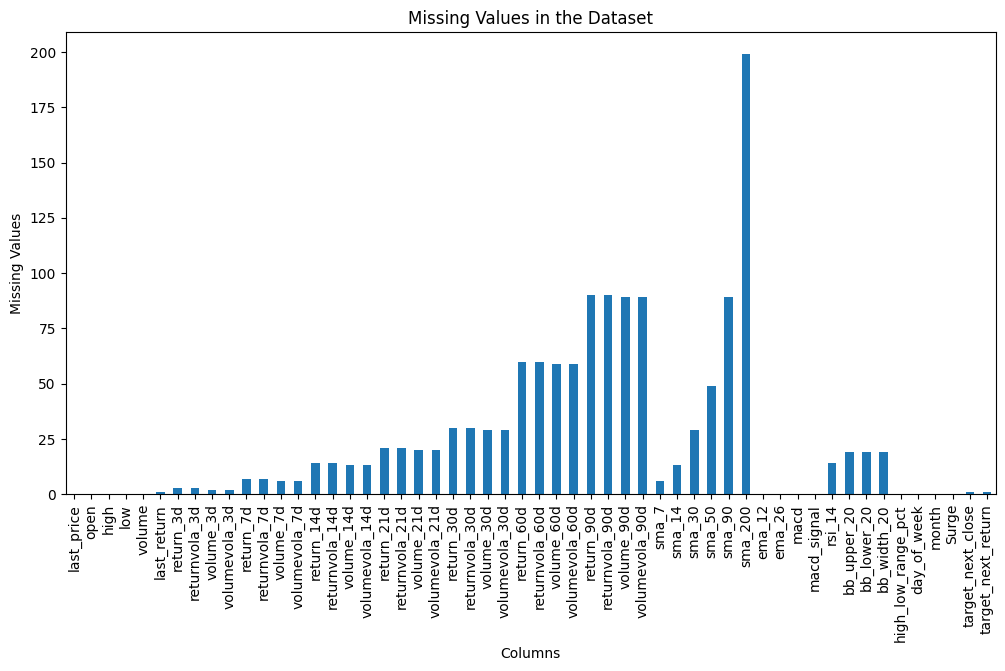

In [46]:
from pathlib import Path

#visualizing the missing values in the dataset
import matplotlib.pyplot as plt
df.isnull().sum().plot(kind='bar', figsize=(12, 6), title='Missing Values in the Dataset')
plt.xlabel('Columns')
plt.ylabel('Missing Values')
output_path = Path('../03.results/eda_visualizations/missing_values.png')
output_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(output_path, dpi=120, bbox_inches='tight')
plt.show()

In [47]:
#handling null values in the dataset
df.isnull().sum()

last_price              0
open                    0
high                    0
low                     0
volume                  0
last_return             1
return_3d               3
returnvola_3d           3
volume_3d               2
volumevola_3d           2
return_7d               7
returnvola_7d           7
volume_7d               6
volumevola_7d           6
return_14d             14
returnvola_14d         14
volume_14d             13
volumevola_14d         13
return_21d             21
returnvola_21d         21
volume_21d             20
volumevola_21d         20
return_30d             30
returnvola_30d         30
volume_30d             29
volumevola_30d         29
return_60d             60
returnvola_60d         60
volume_60d             59
volumevola_60d         59
return_90d             90
returnvola_90d         90
volume_90d             89
volumevola_90d         89
sma_7                   6
sma_14                 13
sma_30                 29
sma_50                 49
sma_90      

In [48]:
target_cols = ["target_next_close", "target_next_return"]
feature_cols = [c for c in df.columns if c not in target_cols]
n_before = len(df)
df = df.dropna(subset=feature_cols)            # remove warm-up rows, keep the last unlabeled row
print("rows:", n_before, "->", len(df), "| unlabeled rows kept:", df[target_cols].isna().any(axis=1).sum())

rows: 2436 -> 2237 | unlabeled rows kept: 1


In [49]:
df.isna().sum()

last_price            0
open                  0
high                  0
low                   0
volume                0
last_return           0
return_3d             0
returnvola_3d         0
volume_3d             0
volumevola_3d         0
return_7d             0
returnvola_7d         0
volume_7d             0
volumevola_7d         0
return_14d            0
returnvola_14d        0
volume_14d            0
volumevola_14d        0
return_21d            0
returnvola_21d        0
volume_21d            0
volumevola_21d        0
return_30d            0
returnvola_30d        0
volume_30d            0
volumevola_30d        0
return_60d            0
returnvola_60d        0
volume_60d            0
volumevola_60d        0
return_90d            0
returnvola_90d        0
volume_90d            0
volumevola_90d        0
sma_7                 0
sma_14                0
sma_30                0
sma_50                0
sma_90                0
sma_200               0
ema_12                0
ema_26          

In [50]:
#removing row atget has null values in the dataset
from numpy import mean
df['target_next_close'] = df['target_next_close'].replace(np.nan, mean(df['target_next_close']))
df['target_next_return'] = df['target_next_return'].replace(np.nan, mean(df['target_next_return']))

In [51]:
df.isna().sum()

last_price            0
open                  0
high                  0
low                   0
volume                0
last_return           0
return_3d             0
returnvola_3d         0
volume_3d             0
volumevola_3d         0
return_7d             0
returnvola_7d         0
volume_7d             0
volumevola_7d         0
return_14d            0
returnvola_14d        0
volume_14d            0
volumevola_14d        0
return_21d            0
returnvola_21d        0
volume_21d            0
volumevola_21d        0
return_30d            0
returnvola_30d        0
volume_30d            0
volumevola_30d        0
return_60d            0
returnvola_60d        0
volume_60d            0
volumevola_60d        0
return_90d            0
returnvola_90d        0
volume_90d            0
volumevola_90d        0
sma_7                 0
sma_14                0
sma_30                0
sma_50                0
sma_90                0
sma_200               0
ema_12                0
ema_26          

In [52]:
ok_ret = np.allclose(df["target_next_return"].iloc[:-1], df["last_return"].shift(-1).iloc[:-1])
ok_close = np.allclose(df["target_next_close"].iloc[:-1], df["last_price"].shift(-1).iloc[:-1])
print("target_next_return == next day's last_return:", ok_ret)
print("target_next_close  == next day's last_price :", ok_close)

target_next_return == next day's last_return: True
target_next_close  == next day's last_price : True


i don't scale the  data bcz i will use random forest algorithm

In [53]:
print("Surge == (return>0):", (df["Surge"] == (df["last_return"] > 0)).mean().round(3))
print("Surge == (close>open):", (df["Surge"] == (df["last_price"] > df["open"])).mean().round(3))
lab = df.dropna(subset=["target_next_return"])
print(pd.crosstab(lab["Surge"], lab["target_next_return"] > 0, normalize="index").round(3))

Surge == (return>0): 0.776
Surge == (close>open): 0.774
target_next_return  False  True 
Surge                           
0                   0.498  0.502
1                   0.521  0.479


In [54]:
r = df["target_next_return"]
df["target_direction"] = (r > 0).astype(float).where(r.notna())
print(df["target_direction"].value_counts(dropna=False))

target_direction
0.0    1143
1.0    1094
Name: count, dtype: int64


{Timestamp('2021-02-05 00:00:00'): 0.332, Timestamp('2020-08-23 00:00:00'): 0.319, Timestamp('2021-09-22 00:00:00'): 0.309}
{Timestamp('2021-05-19 00:00:00'): -0.397, Timestamp('2025-10-10 00:00:00'): -0.274, Timestamp('2020-09-03 00:00:00'): -0.262}


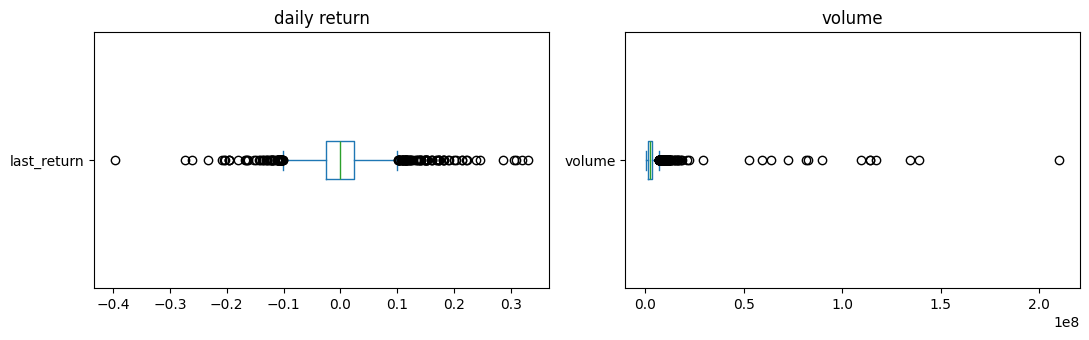

In [59]:
print(df["last_return"].nlargest(3).round(3).to_dict())
print(df["last_return"].nsmallest(3).round(3).to_dict())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df["last_return"].plot.box(ax=ax[0], vert=False); ax[0].set_title("daily return")
df["volume"].plot.box(ax=ax[1], vert=False); ax[1].set_title("volume")
plt.savefig("../03.results/eda_visualizations/return_volume_boxplots.png", dpi=130, bbox_inches='tight')
plt.tight_layout(); plt.show()

The largest moves are real market events, so they are kept. Volume is heavily right-skewed.

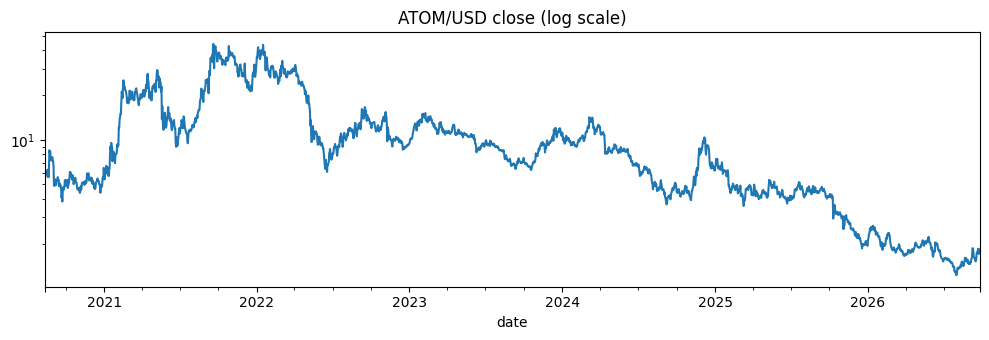

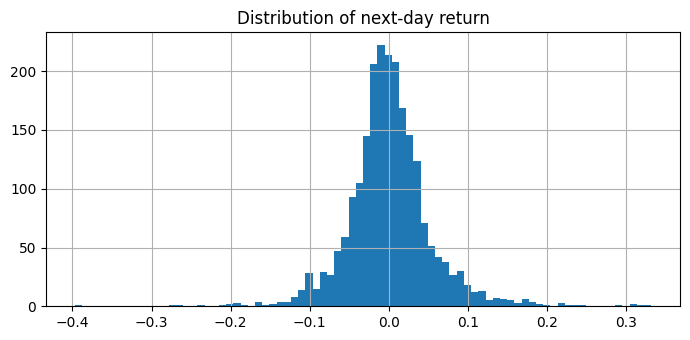

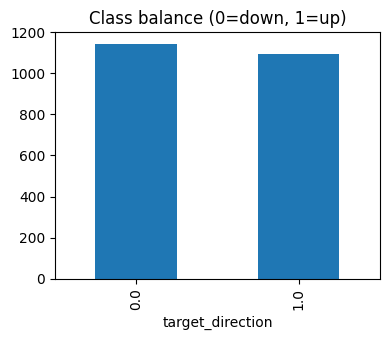

In [57]:
lab = df.dropna(subset=["target_next_return"])
fig, ax = plt.subplots(figsize=(10, 3.5)); df["last_price"].plot(ax=ax, logy=True)
ax.set_title("ATOM/USD close (log scale)"); plt.tight_layout(); fig.savefig("../03.results/eda_visualizations/price_history.png", dpi=130); plt.show()
fig, ax = plt.subplots(figsize=(7, 3.5)); lab["target_next_return"].hist(bins=80, ax=ax)
ax.set_title("Distribution of next-day return"); plt.tight_layout(); fig.savefig("../03.results/eda_visualizations/return_distribution.png", dpi=130); plt.show()
fig, ax = plt.subplots(figsize=(4, 3.5)); lab["target_direction"].value_counts().sort_index().plot.bar(ax=ax)
ax.set_title("Class balance (0=down, 1=up)"); plt.tight_layout(); fig.savefig("../03.results/eda_visualizations/class_balance.png", dpi=130); plt.show()

In [58]:
# saving the preprocessed data to a new CSV file
df.to_csv('../03.results/outputs/ATOM_USD_ML_features_preprocessed.csv', index=False)